# Credit Card Fraud Detection — Model Training and Evaluation

**Project:** Credit Card Fraud Detection  
**Purpose:** Reproduce the final project's `train_model.py` pipeline in Google Colab and export the model files required by `app.py`.

This notebook follows the final ZIP project exactly:
1. Load and explore `creditcard.csv`.
2. Split features and target using a stratified 80:20 split (`random_state=42`).
3. Scale **Amount only**. Fit the scaler on training data only.
4. Train Logistic Regression and Random Forest with the parameters in `train_model.py`.
5. Evaluate both models and generate the same evaluation outputs.
6. Save model files and JSON results for the Streamlit application.

Run the cells from top to bottom. No GPU is required.

## 1. Install and import required libraries
The packages below are the libraries used by the final project training script.

In [1]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
import os
import json
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    average_precision_score,
    classification_report
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("/content/models", exist_ok=True)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload the dataset

Upload the **`creditcard.csv`** file from the `dataset` folder in your final project ZIP.

The notebook expects the original dataset with the columns `Time`, `V1` to `V28`, `Amount`, and `Class`.

In [3]:
uploaded = files.upload()

csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if "creditcard.csv" in csv_files:
    dataset_filename = "creditcard.csv"
elif len(csv_files) == 1:
    dataset_filename = csv_files[0]
else:
    raise ValueError("Please upload exactly one dataset CSV named creditcard.csv.")

df = pd.read_csv(dataset_filename)
print("Dataset loaded:", dataset_filename)
print("Dataset shape:", df.shape)
display(df.head())

Saving creditcard.csv to creditcard (1).csv
Dataset loaded: creditcard (1).csv
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Stage 1 — Data exploration and analysis
This section performs the same basic EDA as `train_model.py`. These checks and charts are for understanding the dataset; they do not change the model training data.

In [4]:
print("=" * 65)
print("DATASET SHAPE")
print("=" * 65)
print(f"Total rows (transactions): {df.shape[0]:,}")
print(f"Total columns: {df.shape[1]}")

print("\nCOLUMN INFORMATION")
df.info()

print("\nMISSING VALUES")
missing_values = df.isnull().sum()
total_missing = int(missing_values.sum())
print(missing_values[missing_values > 0] if total_missing > 0 else "No missing values found.")
print("Total missing values:", total_missing)

print("\nCLASS DISTRIBUTION")
class_counts = df["Class"].value_counts().sort_index()
legit_count = int(class_counts.get(0, 0))
fraud_count = int(class_counts.get(1, 0))
total_transactions = len(df)
print(f"Class 0 (Legitimate): {legit_count:,} ({legit_count/total_transactions*100:.3f}%)")
print(f"Class 1 (Fraudulent): {fraud_count:,} ({fraud_count/total_transactions*100:.3f}%)")
print(f"Class imbalance ratio: approximately {legit_count // max(fraud_count, 1)}:1")

DATASET SHAPE
Total rows (transactions): 284,807
Total columns: 31

COLUMN INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19 

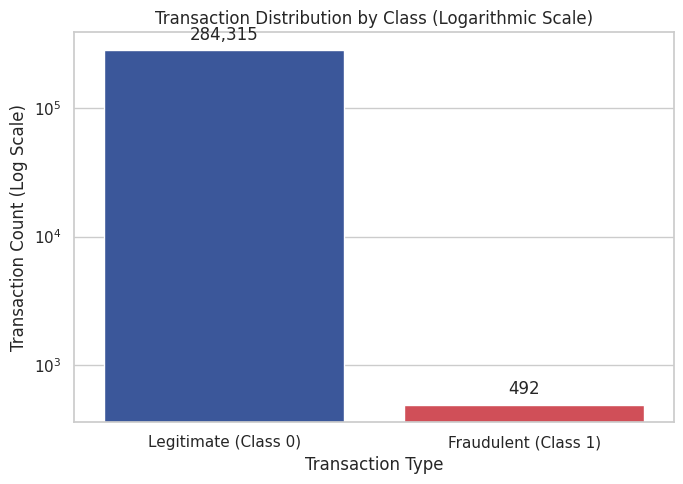

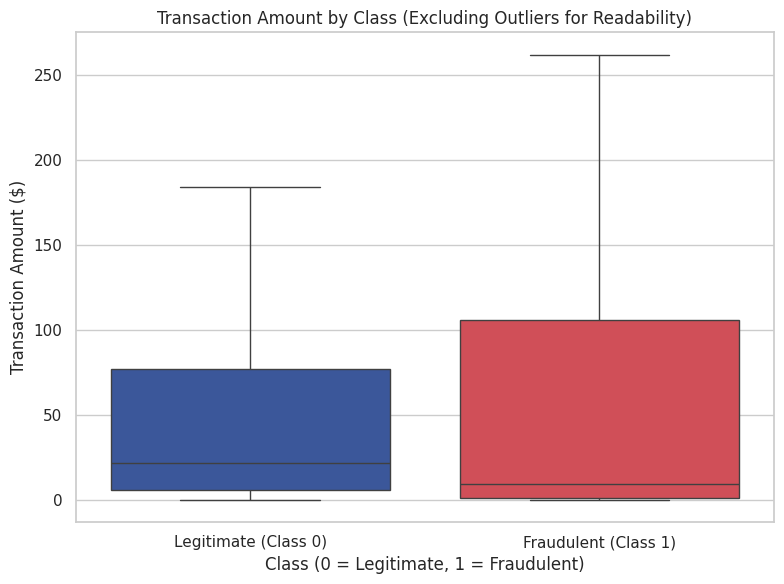


OVERALL AMOUNT STATISTICS


,Amount
count,284807.000000
mean,88.349619
std,250.120109
min,0.000000
25%,5.600000
50%,22.000000
75%,77.165000
max,25691.160000



LEGITIMATE TRANSACTION AMOUNT STATISTICS


,Amount
count,284315.000000
mean,88.291022
std,250.105092
min,0.000000
25%,5.650000
50%,22.000000
75%,77.050000
max,25691.160000



FRAUDULENT TRANSACTION AMOUNT STATISTICS


,Amount
count,492.000000
mean,122.211321
std,256.683288
min,0.000000
25%,1.000000
50%,9.250000
75%,105.890000
max,2125.870000


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [5]:
# Class distribution chart (logarithmic scale)
plt.figure(figsize=(7, 5))
bar_plot = sns.barplot(
    x=["Legitimate (Class 0)", "Fraudulent (Class 1)"],
    y=[legit_count, fraud_count],
    hue=["Legitimate (Class 0)", "Fraudulent (Class 1)"],
    palette=["#2b50aa", "#e63946"],
    legend=False
)
plt.yscale("log")
plt.title("Transaction Distribution by Class (Logarithmic Scale)")
plt.xlabel("Transaction Type")
plt.ylabel("Transaction Count (Log Scale)")
for index, count in enumerate([legit_count, fraud_count]):
    bar_plot.text(index, count * 1.2, f"{count:,}", ha="center")
plt.tight_layout()
plt.savefig("/content/class_distribution.png", dpi=300)
plt.show()

# Transaction amount boxplot
plt.figure(figsize=(8, 6))
sns.boxplot(
    x="Class", y="Amount", hue="Class", data=df,
    palette=["#2b50aa", "#e63946"], legend=False, showfliers=False
)
plt.title("Transaction Amount by Class (Excluding Outliers for Readability)")
plt.xlabel("Class (0 = Legitimate, 1 = Fraudulent)")
plt.ylabel("Transaction Amount ($)")
plt.xticks([0, 1], ["Legitimate (Class 0)", "Fraudulent (Class 1)"])
plt.tight_layout()
plt.savefig("/content/amount_boxplot.png", dpi=300)
plt.show()

print("\nOVERALL AMOUNT STATISTICS")
display(df["Amount"].describe().to_frame())
print("\nLEGITIMATE TRANSACTION AMOUNT STATISTICS")
display(df.loc[df["Class"] == 0, "Amount"].describe().to_frame())
print("\nFRAUDULENT TRANSACTION AMOUNT STATISTICS")
display(df.loc[df["Class"] == 1, "Amount"].describe().to_frame())

## 4. Stage 2 — Data preprocessing and train-test split

- `Class` is the target variable.
- All other columns are input features.
- The split is **80% training and 20% testing**, stratified to preserve the fraud/legitimate class ratio.
- `StandardScaler` is applied to **Amount only**.
- The scaler is fitted only on the training set and then used to transform the test set. This prevents data leakage.

In [6]:
X = df.drop(columns=["Class"])
y = df["Class"]

# Stratified 80:20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train = X_train.copy()
X_test = X_test.copy()

# Scale Amount only; fit on training data only
scaler = StandardScaler()
X_train["Amount"] = scaler.fit_transform(X_train[["Amount"]])
X_test["Amount"] = scaler.transform(X_test[["Amount"]])

print("Preprocessing completed without data leakage.")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("Scaler fitted on training Amount only.")

Preprocessing completed without data leakage.
X_train shape: (227845, 30)
X_test shape: (56962, 30)
y_train shape: (227845,)
y_test shape: (56962,)
Scaler fitted on training Amount only.


## 5. Stage 3 — Train the machine learning models

The model types and hyperparameters below are copied from the final `train_model.py`:
- Logistic Regression with `class_weight='balanced'`.
- Random Forest with `class_weight='balanced_subsample'`.

In [7]:
# Model 1: Logistic Regression
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42,
    solver="liblinear"
)
lr_model.fit(X_train, y_train)
print("Logistic Regression training completed successfully.")

# Model 2: Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
print("Random Forest training completed successfully.")

Logistic Regression training completed successfully.
Random Forest training completed successfully.


## 6. Generate predictions and fraud probabilities
The evaluation uses the models' default class predictions. Probabilities are also generated for ROC-AUC and PR-AUC.

In [8]:
y_pred_lr = lr_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

y_proba_lr = lr_model.predict_proba(X_test)[:, 1]
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print("Predictions and probability scores generated.")

Predictions and probability scores generated.


## 7. Stage 4 — Evaluate both models
Metrics are calculated for the fraud class (`Class = 1`) where relevant. Actual values are produced by this run; do not manually type or assume metric values.

In [9]:
# Accuracy
lr_accuracy = float(accuracy_score(y_test, y_pred_lr))
rf_accuracy = float(accuracy_score(y_test, y_pred_rf))

# Fraud-class precision, recall and F1
lr_precision = float(precision_score(y_test, y_pred_lr, pos_label=1, zero_division=0))
rf_precision = float(precision_score(y_test, y_pred_rf, pos_label=1, zero_division=0))
lr_recall = float(recall_score(y_test, y_pred_lr, pos_label=1, zero_division=0))
rf_recall = float(recall_score(y_test, y_pred_rf, pos_label=1, zero_division=0))
lr_f1 = float(f1_score(y_test, y_pred_lr, pos_label=1, zero_division=0))
rf_f1 = float(f1_score(y_test, y_pred_rf, pos_label=1, zero_division=0))

# Confusion matrices
lr_cm = confusion_matrix(y_test, y_pred_lr, labels=[0, 1])
rf_cm = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])

# Ranking metrics
lr_roc_auc = float(roc_auc_score(y_test, y_proba_lr))
rf_roc_auc = float(roc_auc_score(y_test, y_proba_rf))
lr_pr_auc = float(average_precision_score(y_test, y_proba_lr))
rf_pr_auc = float(average_precision_score(y_test, y_proba_rf))

comparison_data = {
    "Metric": [
        "Accuracy",
        "Precision (Fraud)",
        "Recall (Fraud)",
        "F1-Score (Fraud)",
        "ROC-AUC Score",
        "PR-AUC (Avg Precision)",
        "True Positives (Frauds Caught)",
        "False Positives (False Alarms)",
        "False Negatives (Frauds Missed)"
    ],
    "Logistic Regression": [
        f"{lr_accuracy * 100:.2f}%",
        f"{lr_precision * 100:.2f}%",
        f"{lr_recall * 100:.2f}%",
        f"{lr_f1:.4f}",
        f"{lr_roc_auc:.4f}",
        f"{lr_pr_auc:.4f}",
        f"{lr_cm[1, 1]} / {lr_cm[1].sum()}",
        f"{lr_cm[0, 1]:,}",
        f"{lr_cm[1, 0]}"
    ],
    "Random Forest": [
        f"{rf_accuracy * 100:.2f}%",
        f"{rf_precision * 100:.2f}%",
        f"{rf_recall * 100:.2f}%",
        f"{rf_f1:.4f}",
        f"{rf_roc_auc:.4f}",
        f"{rf_pr_auc:.4f}",
        f"{rf_cm[1, 1]} / {rf_cm[1].sum()}",
        f"{rf_cm[0, 1]:,}",
        f"{rf_cm[1, 0]}"
    ]
}

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)

,Metric,Logistic Regression,Random Forest
0,Accuracy,97.54%,99.94%
1,Precision (Fraud),6.07%,84.21%
2,Recall (Fraud),91.84%,81.63%
3,F1-Score (Fraud),0.1139,0.8290
4,ROC-AUC Score,0.9718,0.9585
5,PR-AUC (Avg Precision),0.7090,0.8452
6,True Positives (Frauds Caught),90 / 98,80 / 98
7,False Positives (False Alarms),"1,392",15
8,False Negatives (Frauds Missed),8,18


In [11]:
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_lr, zero_division=0))

print("RANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_rf, zero_division=0))

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.84      0.82      0.83        98

    accuracy                           1.00     56962
   macro avg       0.92      0.91      0.91     56962
weighted avg       1.00      1.00      1.00     56962



## 8. Evaluation visualizations
Confusion matrices show correct and incorrect classifications. The ROC curve compares true-positive rate and false-positive rate at different probability thresholds.

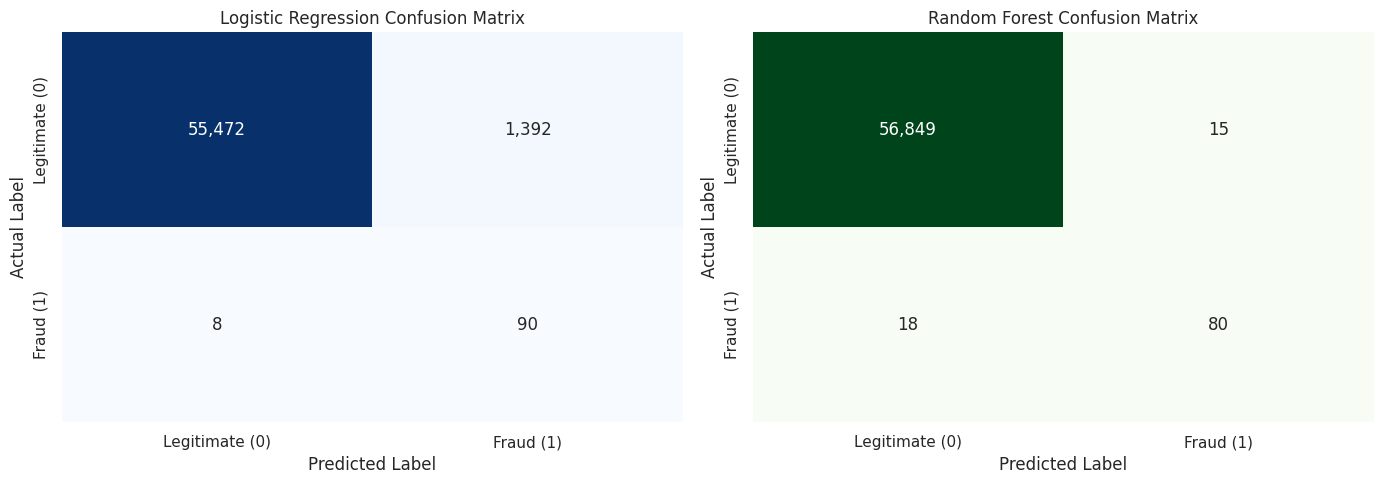

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    lr_cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
    xticklabels=["Legitimate (0)", "Fraud (1)"],
    yticklabels=["Legitimate (0)", "Fraud (1)"]
)
axes[0].set_title("Logistic Regression Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

sns.heatmap(
    rf_cm, annot=True, fmt=",d", cmap="Greens", cbar=False, ax=axes[1],
    xticklabels=["Legitimate (0)", "Fraud (1)"],
    yticklabels=["Legitimate (0)", "Fraud (1)"]
)
axes[1].set_title("Random Forest Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.savefig("/content/confusion_matrices.png", dpi=300)
plt.show()

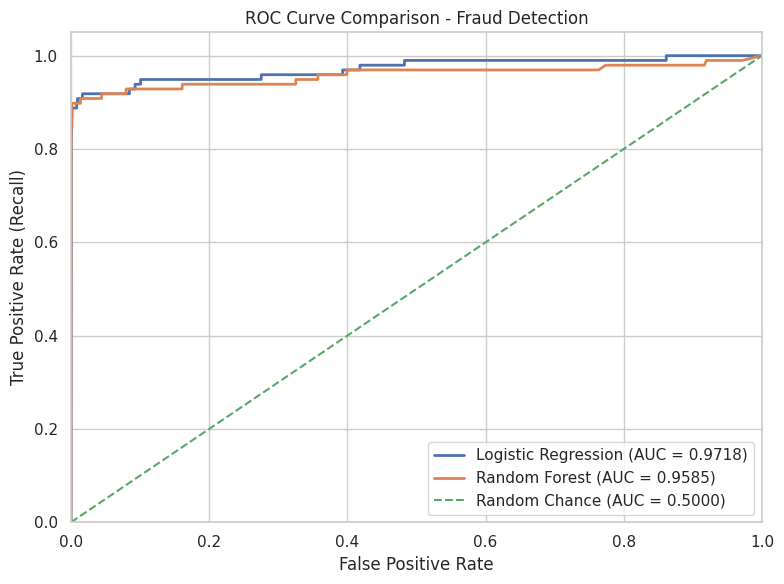

In [12]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, lw=2, label=f"Logistic Regression (AUC = {lr_roc_auc:.4f})")
plt.plot(fpr_rf, tpr_rf, lw=2, label=f"Random Forest (AUC = {rf_roc_auc:.4f})")
plt.plot([0, 1], [0, 1], lw=1.5, linestyle="--", label="Random Chance (AUC = 0.5000)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve Comparison - Fraud Detection")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("/content/roc_curves.png", dpi=300)
plt.show()

## 9. Save evaluation results and model files

The output filenames match the final Streamlit application's expected model folder:
- `logistic_regression_model.joblib`
- `random_forest_model.joblib`
- `fraud_model.joblib` (same Random Forest model used as the primary model)
- `standard_scaler.joblib`
- `evaluation_results.json`
- `metrics.json`

The notebook also saves the EDA and evaluation charts.

In [13]:
evaluation_results = {
    "models": {
        "Logistic Regression": {
            "accuracy": lr_accuracy,
            "precision": lr_precision,
            "recall": lr_recall,
            "f1_score": lr_f1,
            "roc_auc": lr_roc_auc,
            "pr_auc": lr_pr_auc,
            "confusion_matrix": lr_cm.tolist(),
            "true_positives": int(lr_cm[1, 1]),
            "false_positives": int(lr_cm[0, 1]),
            "false_negatives": int(lr_cm[1, 0]),
            "true_negatives": int(lr_cm[0, 0])
        },
        "Random Forest": {
            "accuracy": rf_accuracy,
            "precision": rf_precision,
            "recall": rf_recall,
            "f1_score": rf_f1,
            "roc_auc": rf_roc_auc,
            "pr_auc": rf_pr_auc,
            "confusion_matrix": rf_cm.tolist(),
            "true_positives": int(rf_cm[1, 1]),
            "false_positives": int(rf_cm[0, 1]),
            "false_negatives": int(rf_cm[1, 0]),
            "true_negatives": int(rf_cm[0, 0])
        }
    },
    "test_set_summary": {
        "total_test_transactions": int(len(y_test)),
        "total_test_fraud": int(y_test.sum()),
        "total_test_legit": int((y_test == 0).sum())
    }
}

with open("/content/models/evaluation_results.json", "w") as f:
    json.dump(evaluation_results, f, indent=2)

app_metrics = {
    "roc_auc": rf_roc_auc,
    "pr_auc": rf_pr_auc,
    "optimal_threshold": 0.50,
    "optimal_metrics": {
        "precision_fraud": rf_precision,
        "recall_fraud": rf_recall,
        "f1_fraud": rf_f1,
        "confusion_matrix": rf_cm.tolist(),
        "classification_report": classification_report(
            y_test, y_pred_rf, output_dict=True, zero_division=0
        )
    },
    "comparison": evaluation_results["models"]
}

with open("/content/models/metrics.json", "w") as f:
    json.dump(app_metrics, f, indent=2)

joblib.dump(lr_model, "/content/models/logistic_regression_model.joblib")
joblib.dump(rf_model, "/content/models/random_forest_model.joblib")
joblib.dump(rf_model, "/content/models/fraud_model.joblib")
joblib.dump(scaler, "/content/models/standard_scaler.joblib")

print("All model and evaluation files saved.")

All model and evaluation files saved.


## 10. Verify the saved files
Check that all six files are present before downloading.

In [14]:
expected_files = [
    "logistic_regression_model.joblib",
    "random_forest_model.joblib",
    "fraud_model.joblib",
    "standard_scaler.joblib",
    "evaluation_results.json",
    "metrics.json"
]

for filename in expected_files:
    filepath = os.path.join("/content/models", filename)
    print(("OK" if os.path.exists(filepath) else "MISSING"), filename)

print("\nRandom Forest test metrics:")
print("Accuracy :", f"{rf_accuracy * 100:.2f}%")
print("Precision:", f"{rf_precision * 100:.2f}%")
print("Recall   :", f"{rf_recall * 100:.2f}%")
print("F1-score :", f"{rf_f1:.4f}")
print("ROC-AUC  :", f"{rf_roc_auc:.4f}")
print("PR-AUC   :", f"{rf_pr_auc:.4f}")

OK logistic_regression_model.joblib
OK random_forest_model.joblib
OK fraud_model.joblib
OK standard_scaler.joblib
OK evaluation_results.json
OK metrics.json

Random Forest test metrics:
Accuracy : 99.94%
Precision: 84.21%
Recall   : 81.63%
F1-score : 0.8290
ROC-AUC  : 0.9585
PR-AUC   : 0.8452


## 11. Download the trained models for the final project

This creates one ZIP containing the `models` folder. Download it and replace the existing `models` folder in your project **only after checking the training output**.

**Important:** Your Streamlit app must use the same input feature order as the dataset (`Time`, `V1`–`V28`, `Amount`) and the saved scaler must transform only `Amount`. Do not fit a new scaler on individual app inputs.

In [15]:
models_zip = "/content/trained_models_for_streamlit.zip"

with zipfile.ZipFile(models_zip, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in os.listdir("/content/models"):
        full_path = os.path.join("/content/models", filename)
        zipf.write(full_path, arcname=os.path.join("models", filename))

print("Created:", models_zip)
files.download(models_zip)

Created: /content/trained_models_for_streamlit.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>